# Solar Flare Forecasting with NOAA GOES-18

Can recent solar X-ray measurements help estimate whether an M-class-or-stronger flare will begin in the next 60 minutes? This notebook presents real NOAA observations, flare-event context, and an initial chronological model evaluation. It is retrospective portfolio analysis, not an operational warning system. Labels use catalogued flare **start times**; features use only measurements at or before each timestamp.

**Coverage:** June 2022–December 2025 · **Split:** train 2022–2023, validation 2024, test 2025.

In [ ]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA, REPORTS = ROOT / 'data', ROOT / 'reports'
features = pd.read_csv(DATA / 'processed' / 'goes18_forecast_features.csv', parse_dates=['time_utc'])
features['year'] = features['time_utc'].dt.year
print(f"{len(features):,} usable rows; {features['target_m_or_x_start_next_60m'].mean():.2%} positive windows")
display(features.groupby('year').agg(rows=('target_m_or_x_start_next_60m','size'), positive_rate=('target_m_or_x_start_next_60m','mean')).round(3))

350,060 usable rows; 5.30% positive windows


,rows,positive_rate
year,,
2022,45024,0.020
2023,102574,0.040
2024,99696,0.096
2025,102766,0.039


## Signal and event context

The blue line is quality-screened GOES-18 XRS-B irradiance. Vertical markers are cataloged M/X flare starts. The vertical axis is logarithmic because the signal spans several orders of magnitude.

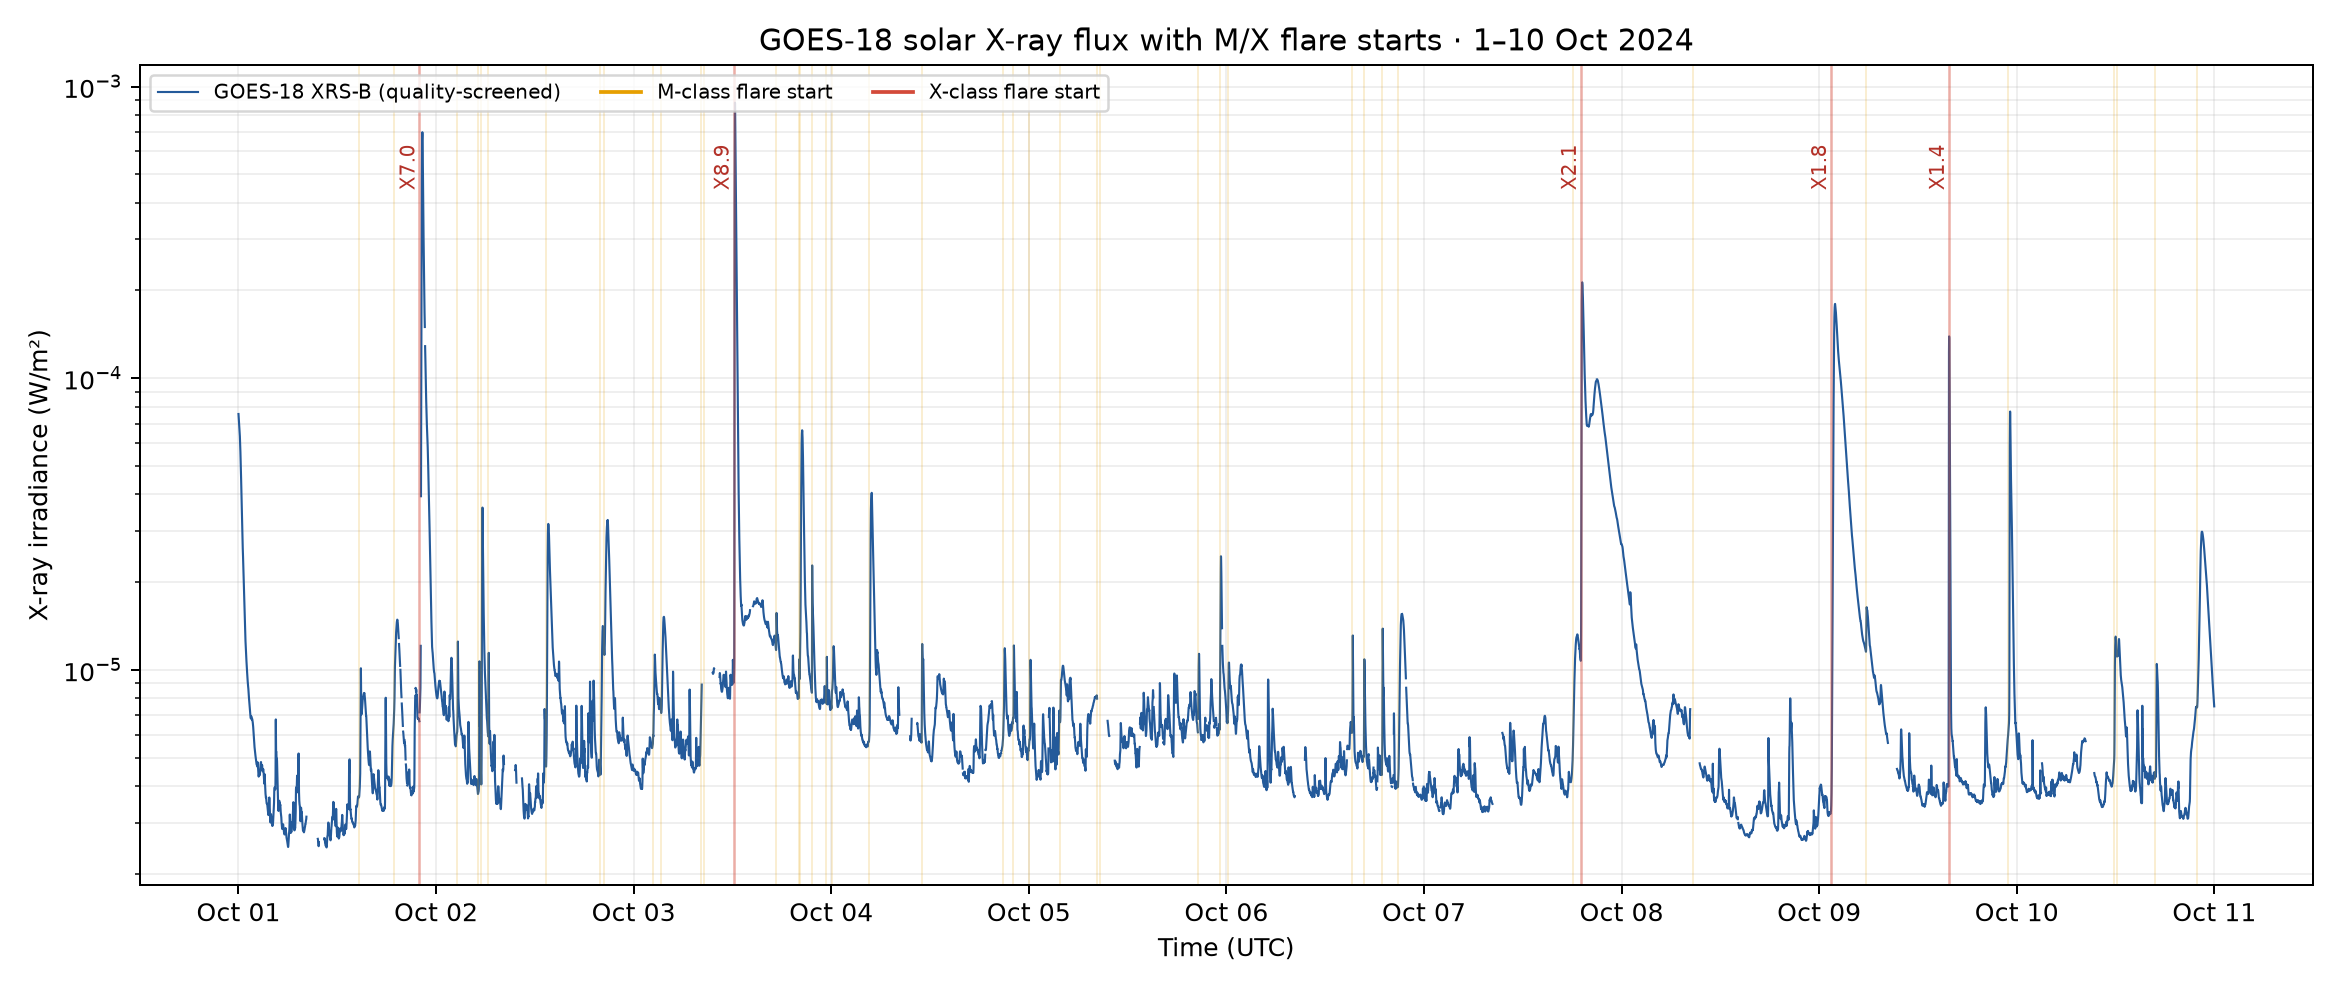

In [ ]:
display(Image(filename=str(REPORTS / 'figures' / 'goes18_xray_and_flare_onsets_oct2024.png')))

## Flare activity by year

The 2022 series begins on 17 June, when GOES-18 data starts. Counts are descriptive; annual rates also reflect the solar cycle.

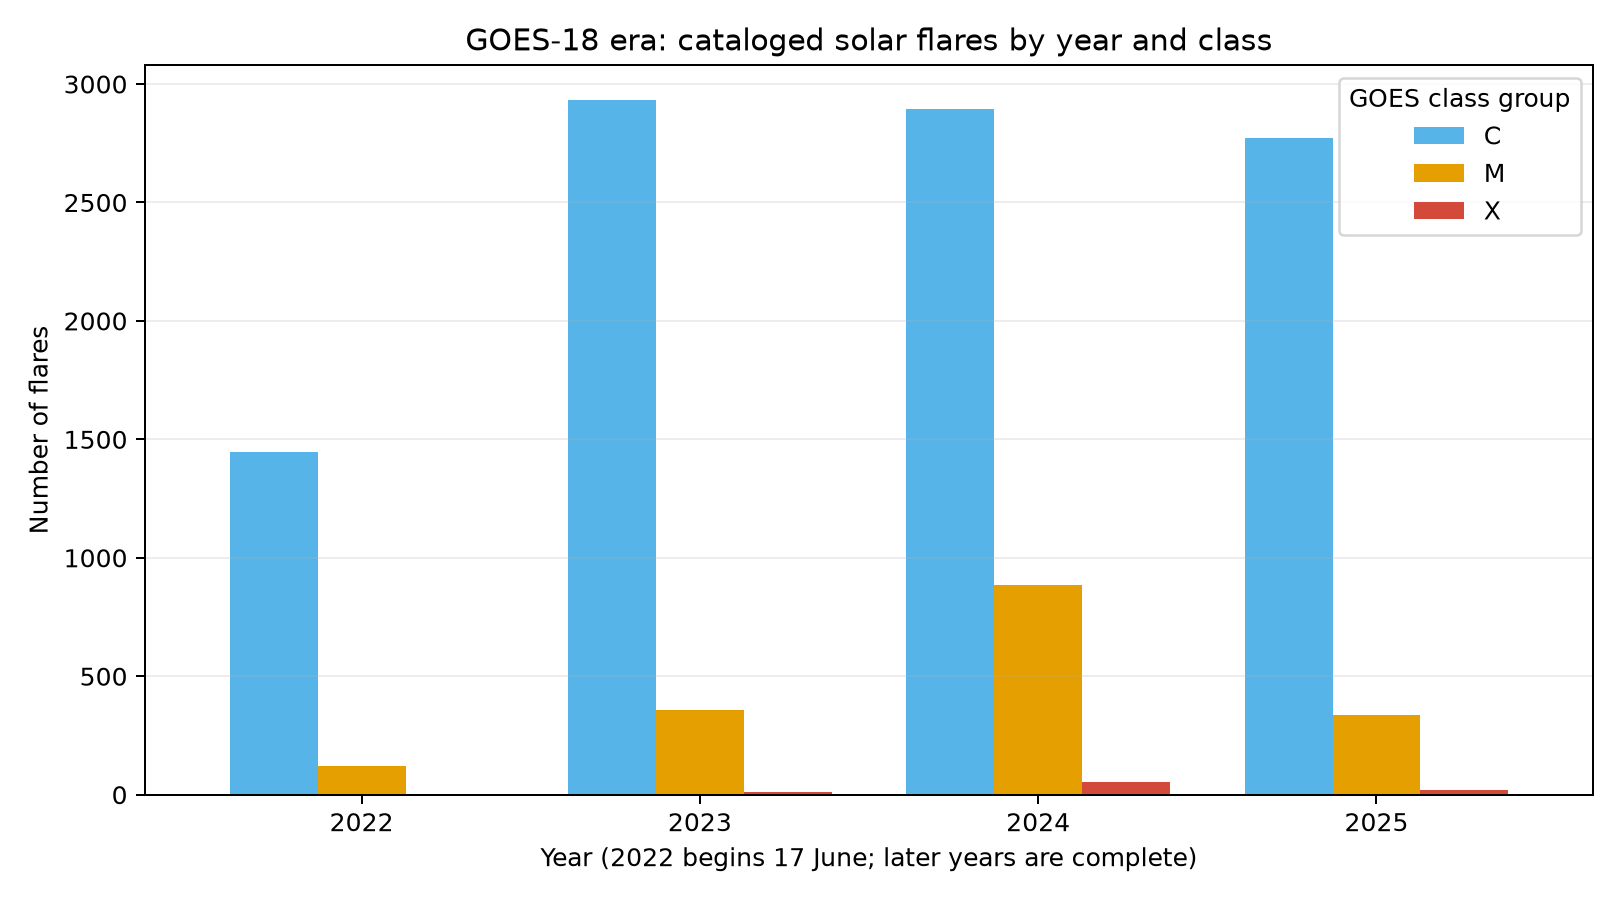

In [ ]:
display(Image(filename=str(REPORTS / 'figures' / 'flare_counts_by_year.png')))

## Model performance on the held-out 2025 year

Thresholds were selected on 2024 validation data. Average precision is compared with the positive-window prevalence baseline. Five-minute windows overlap, so these results are not event-level warning skill.

,Average precision,ROC-AUC,Precision,Recall,F1,Alert rate
Model,,,,,,
Logistic regression,0.104,0.763,0.132,0.187,0.155,0.055
Histogram gradient boosting,0.106,0.760,0.127,0.297,0.178,0.090


Prevalence baseline AP: 0.039


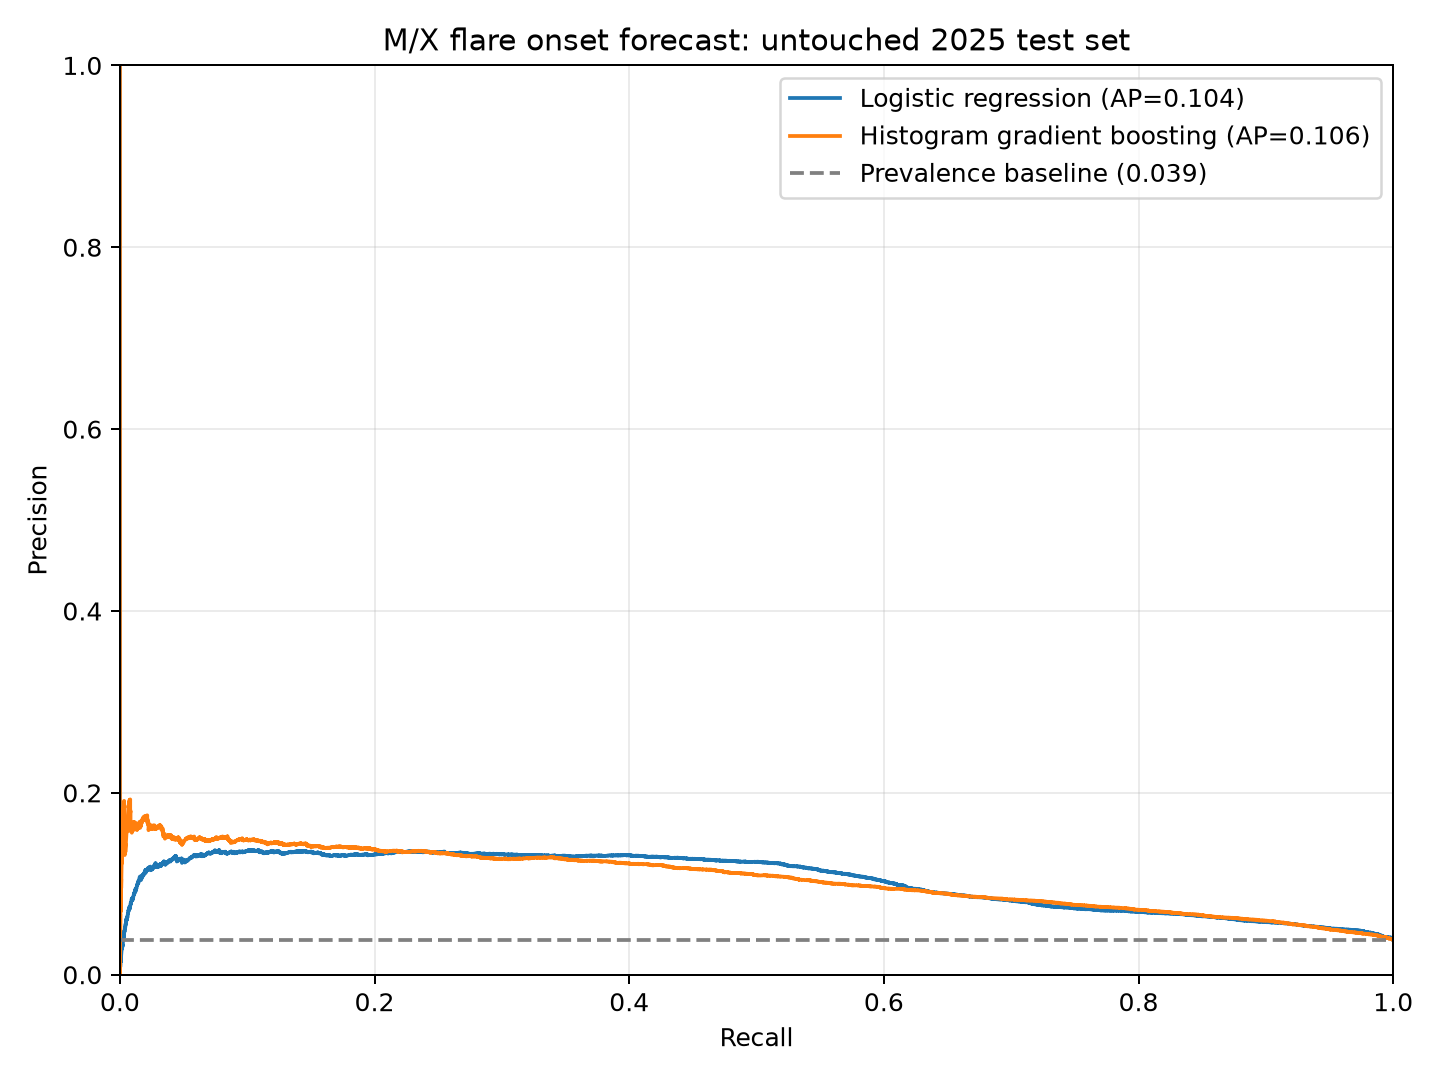

In [ ]:
with (REPORTS / 'model_evaluation.json').open(encoding='utf-8') as f:
    evaluation = json.load(f)
rows=[]
for name, splits in evaluation['models'].items():
    m=splits['test_2025']
    rows.append({'Model':name,'Average precision':m['average_precision'],'ROC-AUC':m['roc_auc'],'Precision':m['precision_at_threshold'],'Recall':m['recall_at_threshold'],'F1':m['f1_at_threshold'],'Alert rate':m['alert_rate']})
display(pd.DataFrame(rows).set_index('Model').round(3))
print(f"Prevalence baseline AP: {evaluation['test_positive_rate_baseline_average_precision']:.3f}")
display(Image(filename=str(REPORTS / 'figures' / 'precision_recall_2025.png')))

## Monthly performance in 2025

The decision threshold stays fixed across the final test year. Alert burden and precision vary over time, so a single summary score hides important behaviour.

,rows,positive_windows,alerts,positive_rate,alert_rate,precision,recall
month,,,,,,,
1,8917,500,1875,0.056,0.210,0.107,0.400
2,7913,563,1437,0.071,0.182,0.193,0.492
3,8256,235,348,0.028,0.042,0.138,0.204
4,8410,374,777,0.044,0.092,0.185,0.385
5,8868,265,111,0.030,0.013,0.207,0.087
6,8619,228,446,0.026,0.052,0.067,0.132
7,8906,60,65,0.007,0.007,0.031,0.033
8,8835,461,1563,0.052,0.177,0.109,0.371
9,7996,163,371,0.020,0.046,0.124,0.282


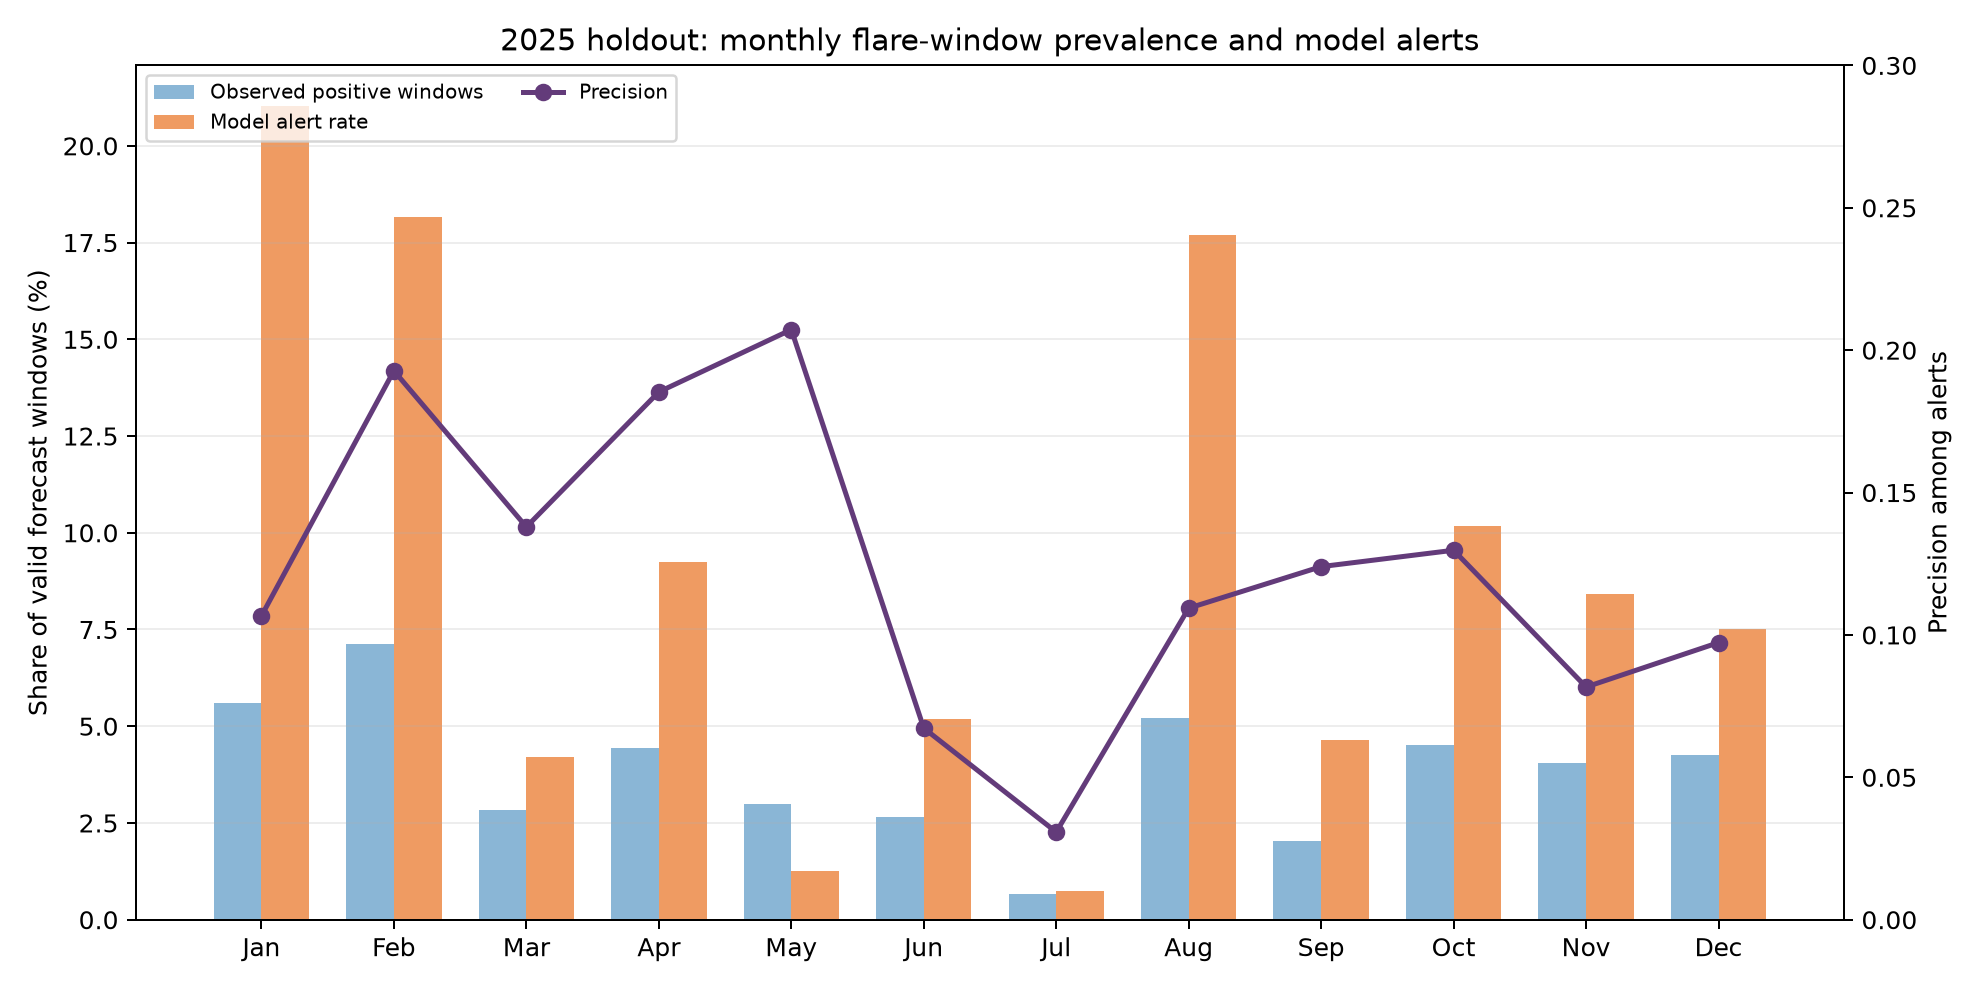

In [ ]:
monthly = pd.read_csv(REPORTS / 'tables' / 'monthly_test_metrics_2025.csv', index_col='month')
display(monthly.round(3))
display(Image(filename=str(REPORTS / 'figures' / 'monthly_alert_performance_2025.png')))

## Limitations and next steps

The first models rank positive windows above the prevalence baseline, but false alerts remain frequent. Next: group adjacent predictions into alert episodes, score distinct flare detection and lead time, compare simple flux-threshold baselines, and check calibration and uncertainty. Results are retrospective and should not be presented as real-time warning capability. See `reports/portfolio_summary.md` for the full interpretation.